# 02 — Qwen Baseline: classification and transcription

We evaluate the base Qwen model without a trained adapter using the validation crops prepared in notebook 01.

The workflow checks the environment, loads the model in 4-bit NF4 when inference is needed, tests one crop, and evaluates the full validation set. Results are saved after each region.

Completed results are reused when the validation manifest and evaluation settings match. We keep the existing experiment directory and dataset split throughout.

In [1]:
import importlib.metadata as metadata
import json
import sys
from pathlib import Path

import torch
from IPython.display import display
from PIL import Image

CWD = Path.cwd().resolve()
CANDIDATES = [candidate for parent in (CWD, *CWD.parents) for candidate in (parent, parent / "src")]
PACKAGE = next(
    (
        candidate
        for candidate in CANDIDATES
        if (candidate / "rukopys" / "models.py").is_file() and (candidate / "work").is_dir()
    ),
    None,
)

if PACKAGE is None:
    raise FileNotFoundError(
        "Open the notebook from the project directory or one of its subdirectories. "
        "Place the rukopys package inside the existing src directory, next to work."
    )

if str(PACKAGE) not in sys.path:
    sys.path.insert(0, str(PACKAGE))

from rukopys.config import CLASS_PROMPT, PROMPTS
from rukopys.evaluate import evaluate
from rukopys.models import generate, load_qwen
from rukopys.utils import digest, file_digest, read_json

ROOT = (PACKAGE / "work").resolve()
RUN_FULL_EVALUATION = True
REUSE_COMPLETED_RESULTS = True
MAX_PIXELS = 512 * 512
MAX_NEW_TOKENS = 512
OUTPUT = ROOT / "outputs" / "baseline.json"

for name in ("project.json", "data/validation.json", "data/train.json"):
    if not (ROOT / name).is_file():
        raise FileNotFoundError(f"Missing prepared artifact: work/{name}")

print("Python:", sys.version.split()[0])
print("Source directory:", PACKAGE.name)
print("Experiment directory:", ROOT.relative_to(PACKAGE))
print("Evaluation output:", OUTPUT.relative_to(PACKAGE))

Python: 3.12.5
Source directory: src
Experiment directory: work
Evaluation output: work\outputs\baseline.json


## Check the environment and saved results

We keep the existing Python environment without installing or upgrading packages automatically. Missing dependencies should be installed in the selected kernel before restarting it.

Before loading Qwen, we check any saved evaluation against the current validation manifest, prompts, token budget, model revision, and pixel budget. A mismatch stops execution to protect the existing experiment.

When a complete matching result file is available, the remaining cells reuse its predictions and summary without requiring CUDA inference. Crop contents are not rehashed in this reuse path; this is a view of the saved experiment.

In [2]:
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

for package in (
    "transformers",
    "huggingface_hub",
    "accelerate",
    "peft",
    "bitsandbytes",
    "pillow",
):
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError as exc:
        raise RuntimeError(
            f"Missing dependency: {package}. "
            "Install it in the selected kernel and restart the kernel."
        ) from exc

validation = read_json(ROOT / "data" / "validation.json")
project = read_json(ROOT / "project.json")

if not validation:
    raise RuntimeError("The validation manifest is empty.")

saved = read_json(OUTPUT) if OUTPUT.is_file() else None
USE_SAVED_RESULTS = False

if saved is not None:
    config = saved.get("config", {})
    saved_protocol = config.get("protocol", {})
    expected = {
        "manifest": digest(validation),
        "prompts": PROMPTS,
        "class_prompt": CLASS_PROMPT,
        "max_tokens": MAX_NEW_TOKENS,
    }

    if any(config.get(key) != value for key, value in expected.items()):
        raise ValueError(
            "The saved baseline uses a different manifest or evaluation settings. "
            "Keep baseline.json; use a separate output file for a new experiment."
        )

    if (
        saved_protocol.get("model_id") != project["model_id"]
        or saved_protocol.get("model_revision") != project.get("model_revision")
        or saved_protocol.get("max_pixels") != MAX_PIXELS
        or saved_protocol.get("quantized") is not True
        or saved_protocol.get("adapter_sha256") is not None
    ):
        raise ValueError("The saved baseline uses a different model protocol.")

    saved_results = saved.get("results", [])

    if [row["id"] for row in saved_results] != [
        row["id"] for row in validation[: len(saved_results)]
    ]:
        raise ValueError("The saved evaluation does not match the validation order.")

    USE_SAVED_RESULTS = (
        REUSE_COMPLETED_RESULTS
        and saved.get("complete", False)
        and len(saved_results) == len(validation)
        and "summary" in saved
    )

print("Validation regions:", len(validation))
print("Scorable validation regions:", sum(row["scorable"] for row in validation))
print("Reusing completed evaluation:", USE_SAVED_RESULTS)

if not USE_SAVED_RESULTS:
    if not torch.cuda.is_available():
        raise RuntimeError("Select a kernel with CUDA-enabled PyTorch to run or resume inference.")

    print("GPU:", torch.cuda.get_device_name(0))
    print("Compute capability:", torch.cuda.get_device_capability(0))
    print(
        "Total VRAM (GiB):",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    )
    print(
        "CUDA computation test:",
        (torch.ones(3, device="cuda") * 2).cpu().tolist(),
    )

PyTorch: 2.7.1+cu126
CUDA available: True
transformers: 4.57.6
huggingface_hub: 0.36.2
accelerate: 1.15.0
peft: 0.21.2
bitsandbytes: 0.49.0
pillow: 11.1.0
Validation regions: 5082
Scorable validation regions: 4955
Reusing completed evaluation: True


## Load the base model

We use 4-bit NF4 quantization to reduce model weight memory. The loader selects the compute dtype, and the recorded protocol shows the actual value used. Loading the model successfully does not guarantee that every crop fits in GPU memory.

The model revision is recorded in `work/project.json`. The pixel budget stays consistent across baseline, training, and evaluation.

For a complete matching baseline, we read the saved protocol and skip model loading.

In [3]:
if USE_SAVED_RESULTS:
    protocol = saved["config"]["protocol"]
    print("Reusing the recorded protocol; model loading is skipped.")
else:
    model, processor, protocol = load_qwen(
        ROOT,
        quantized=True,
        max_pixels=MAX_PIXELS,
    )

    print("Allocated VRAM (GiB):", round(torch.cuda.memory_allocated() / 1024**3, 2))
    print("Reserved VRAM (GiB):", round(torch.cuda.memory_reserved() / 1024**3, 2))

print(json.dumps(protocol, ensure_ascii=False, indent=2))

Reusing the recorded protocol; model loading is skipped.
{
  "model_id": "Qwen/Qwen3-VL-4B-Instruct",
  "model_revision": "ebb281ec70b05090aa6165b016eac8ec08e71b17",
  "quantized": true,
  "dtype": "torch.bfloat16",
  "max_pixels": 262144,
  "adapter_sha256": null,
  "packages": {
    "torch": "2.7.1+cu126",
    "transformers": "4.57.6",
    "peft": "0.21.2",
    "bitsandbytes": "0.49.0",
    "pillow": "11.1.0"
  }
}


## Inspect one handwritten crop

Before new or resumed inference, we test classification and transcription on one crop. This checks that generation runs; it is not a quality benchmark. An incorrect prediction is allowed, while a truncated transcription stops execution for review.

When reusing a completed baseline, we display the same crop and its saved predictions instead of generating them again. The reported time and token count then belong to the saved run, and no new runtime check is performed.

Displaying saved predictions; no new inference is performed.


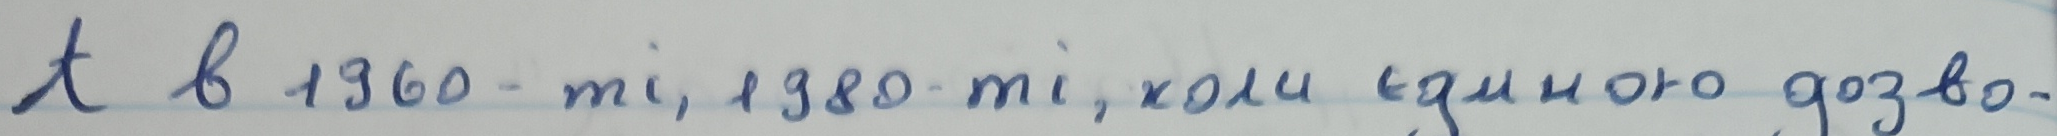

Region ID: 0c8b9a994ea01742bc6173c7
Reference type: handwritten
Predicted type: handwritten
Reference text: А в 1960-ті, 1980-ті, коли єдиною дозво-
Predicted text: т в 1960-ті, 1980-ті, коли єдиного дозво-
Transcription time (seconds): 10.71
Generated tokens: 31
Reached token limit: False


In [4]:
SMOKE_TEST_PASSED = False
sample = next(
    (row for row in validation if row["scorable"] and row["type"] == "handwritten"),
    None,
)

if sample is None:
    sample = next(row for row in validation if row["scorable"] and row["type"] in PROMPTS)

if USE_SAVED_RESULTS:
    saved_sample = next(row for row in saved["results"] if row["id"] == sample["id"])
    classification = saved_sample["classification"]
    transcription = saved_sample["oracle"]
    print("Displaying saved predictions; no new inference is performed.")

    if Path(sample["crop_path"]).is_file():
        with Image.open(sample["crop_path"]) as image:
            display(image.convert("RGB"))
    else:
        print("Crop preview is unavailable; saved predictions are shown below.")
else:
    if file_digest(sample["crop_path"]) != sample["crop_sha256"]:
        raise RuntimeError("The smoke-test crop has changed since preparation.")

    with Image.open(sample["crop_path"]) as image:
        crop = image.convert("RGB")

    display(crop)
    classification = generate(
        model,
        processor,
        crop,
        CLASS_PROMPT,
        max_tokens=32,
    )
    transcription = generate(
        model,
        processor,
        crop,
        PROMPTS[sample["type"]],
        max_tokens=MAX_NEW_TOKENS,
    )
    crop.close()

print("Region ID:", sample["id"])
print("Reference type:", sample["type"])
print("Predicted type:", classification["prediction"])
print("Reference text:", sample["reference"])
print("Predicted text:", transcription["prediction"])
print("Transcription time (seconds):", round(transcription["seconds"], 2))
print("Generated tokens:", transcription["generated_tokens"])
print("Reached token limit:", transcription["hit_token_limit"])

if not USE_SAVED_RESULTS:
    if transcription["hit_token_limit"]:
        raise RuntimeError(
            "Smoke-test transcription reached the token limit. "
            "Review the output before running full evaluation."
        )

    SMOKE_TEST_PASSED = True

## Evaluate the full validation dataset

We first reuse the summary when `REUSE_COMPLETED_RESULTS = True` and a complete matching `baseline.json` is available. This path performs no new model inference and does not rewrite the results file.

Otherwise, `RUN_FULL_EVALUATION = True` runs or resumes evaluation after the runtime check. Completed regions are reused only when the manifest and full evaluation configuration match. Resuming still requires model loading; full inference can take a long time. Keep `baseline.json` to preserve progress.

Classification is evaluated for every region. Oracle-type transcription uses reference types to isolate recognition quality, while routed transcription also includes predicted-type errors. Images and graphs do not require transcription.

We report raw corpus CER and mean region CER separately. These metrics are not directly comparable to an older handwritten-only subset or the complete Kaggle composite score.

Set `RUN_FULL_EVALUATION = False` to prevent full evaluation when no reusable completed result is available. Set `REUSE_COMPLETED_RESULTS = False` to run the runtime check again and let the evaluator validate the current full protocol, including package versions and dtype. Configuration mismatches stop execution.

In [5]:
if USE_SAVED_RESULTS:
    summary = saved["summary"]
    print("Reusing the completed baseline; no new inference is needed.")
    print(json.dumps(summary, ensure_ascii=False, indent=2))
    print("Saved results:", OUTPUT.relative_to(PACKAGE))
elif RUN_FULL_EVALUATION:
    if not globals().get("SMOKE_TEST_PASSED", False):
        raise RuntimeError("Run the smoke-test cell successfully first.")

    summary = evaluate(
        ROOT,
        model,
        processor,
        protocol,
        OUTPUT,
        max_tokens=MAX_NEW_TOKENS,
    )

    print(json.dumps(summary, ensure_ascii=False, indent=2))
    print("Evaluation completed. Results:", OUTPUT.relative_to(PACKAGE))
else:
    print("Smoke test completed. Full evaluation is disabled.")

Reusing the completed baseline; no new inference is needed.
{
  "oracle": {
    "n": 4955,
    "corpus_raw_cer": 0.7770187962538476,
    "mean_region_raw_cer": 0.9334420837426898
  },
  "routed": {
    "n": 4955,
    "corpus_raw_cer": 0.7455432575807192,
    "mean_region_raw_cer": 0.6750975904381371
  },
  "classification_accuracy": 0.9191263282172373,
  "invalid_labels": 0,
  "by_type": {
    "handwritten": {
      "n": 4277,
      "corpus_raw_cer": 0.707224133368616,
      "mean_region_raw_cer": 0.6333557085961372
    },
    "printed": {
      "n": 88,
      "corpus_raw_cer": 2.183644859813084,
      "mean_region_raw_cer": 7.041325857858004
    },
    "formula": {
      "n": 472,
      "corpus_raw_cer": 1.1546627677833576,
      "mean_region_raw_cer": 1.0561353584200837
    },
    "table": {
      "n": 23,
      "corpus_raw_cer": 0.6163934426229508,
      "mean_region_raw_cer": 0.5650560640982617
    },
    "annotation": {
      "n": 95,
      "corpus_raw_cer": 2.2649164677804294,
  